# CIFAR-10 FCN

## 1. Business Understanding

Tarkoitus on oppia käyttämään ja arvioimaan neuroverkko tekniikoita CIFAR-10 datasetin avulla. Tässä työkirjassa käytämmen FCN (Fully Connected Network) mallia.

## 2. Data Understanding

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

In [2]:
import keras
from keras import layers
print(keras.__version__, keras.backend.backend())
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.utils import to_categorical
import pandas as pd
import time

3.15.1 tensorflow


In [3]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

In [4]:
print(f'x_train shape: {x_train.shape}')
print(f'x_test shape:  {x_test.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'y_test shape:  {y_test.shape}')

x_train shape: (50000, 32, 32, 3)
x_test shape:  (10000, 32, 32, 3)
y_train shape: (50000, 1)
y_test shape:  (10000, 1)


Data pitää sisällään 60,000 32x32 värikuvaa. Se on jaettu koulutus ja testi joukkoihin. Koulutusjoukossa on 50,000 ja testijoukossa 10,000 kuvaa. Kuvilla on 10 eri luokkaa. `airplane`, `automobile`, `bird`, `cat`, `deer`, `dog`, `frog`, `horse`, `ship` ja `truck`. Luokilla ei ole päällekkäisyyksiä, esim `automobile` ja `truck` luokissa ei ole samantyyppisiä autoja.
[lähde](https://cave.cs.toronto.edu/kriz/cifar.html)

## 3. Data Preprocessing

In [5]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

mean = x_train.mean(axis=(0, 1, 2))
std = x_train.std(axis=(0, 1, 2))
print("mean:", mean)
print("std: ", std)

x_train = (x_train - mean) / std
x_test = (x_test - mean) / std

X_train = x_train.reshape(50000, 3072)
X_test = x_test.reshape(10000, 3072)

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

mean: [0.4914009  0.48215896 0.4465308 ]
std:  [0.24703279 0.24348423 0.26158753]


## 4. Modeling

### Neuronien ja kerrosten määrien vertailu

Vertaillaan mallin suorityskykyä neuronien ja kerrosten määrän perusteella.
Kokeilussa on `512`, `256` ja `128` neuronin ensimmäinen kerros, toiseen kerroksen kokeiluilla neuronien määrä puolitetaan.

In [6]:
results = []
histories = {}
def build_model(units, n_layers):
    layers = [keras.Input(shape=(3072,))]
    width = units
    for _ in range(n_layers):
        layers.append(keras.layers.Dense(width, activation="relu"))
        width = max(width // 2, 16)
    layers.append(keras.layers.Dense(10, activation="softmax"))
    model = keras.Sequential(layers)
    model.compile(optimizer="adam",
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model

for units in [128, 256, 512]:
    for n_layers in [1, 2]:
        callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,restore_best_weights=True)]
        keras.utils.set_random_seed(42)
        model = build_model(units, n_layers)

        t0 = time.perf_counter()
        history = model.fit(X_train, y_train, epochs=20, batch_size=64,
                            validation_split=0.2, verbose=0, callbacks=callbacks)
        train_time = time.perf_counter() - t0

        test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
        key = f"{units} neuronia, {n_layers} kerrosta"
        histories[key] = history.history
        best_epoch = int(np.argmin(history.history["val_loss"]))

        results.append({
            "neuronit": units,
            "kerrokset": n_layers,
            "parametreja": model.count_params(),
            "aika_s": train_time / len(history.history["loss"]),
            "paras_epookki": best_epoch + 1,
            "epookkeja_ajettu": len(history.history["loss"]),
            "train_acc": history.history["accuracy"][best_epoch],
            "val_acc": history.history["val_accuracy"][best_epoch],
            "ero_train_val": history.history["accuracy"][best_epoch]
                     - history.history["val_accuracy"][best_epoch],
            "test_acc": test_acc,
        })
        print(key, "->", round(test_acc, 4), f"({train_time/len(history.history['loss']):.1f} s)")
df = pd.DataFrame(results)

128 neuronia, 1 kerrosta -> 0.4764 (1.0 s)
128 neuronia, 2 kerrosta -> 0.4796 (1.1 s)
256 neuronia, 1 kerrosta -> 0.4638 (1.4 s)
256 neuronia, 2 kerrosta -> 0.4772 (1.5 s)
512 neuronia, 1 kerrosta -> 0.4654 (2.1 s)
512 neuronia, 2 kerrosta -> 0.4684 (2.3 s)


In [7]:
df

,neuronit,kerrokset,parametreja,aika_s,paras_epookki,epookkeja_ajettu,train_acc,val_acc,ero_train_val,test_acc
0,128,1,394634,1.044468,4,7,0.536700,0.4689,0.067800,0.4764
1,128,2,402250,1.116445,4,7,0.517575,0.4614,0.056175,0.4796
2,256,1,789258,1.380326,3,6,0.522900,0.4706,0.052300,0.4638
3,256,2,820874,1.513693,4,7,0.530150,0.4745,0.055650,0.4772
4,512,1,1578506,2.136471,2,5,0.484575,0.4596,0.024975,0.4654
5,512,2,1707274,2.315438,3,6,0.503475,0.4578,0.045675,0.4684


Testeistä selviää että mallin koko ei juurikaan paranna mallin suorituskykyä, mutta suuremmalla mallilla jossa `512` neuronia ja `2` kerrosta aika on yli kaksinkertainen per epoch. `val_acc` on paras `256` neuronilla jossa 2 kerrosta, toisessa kerroksessa `128` neuronia.

In [8]:
model = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
full_history = model.fit(X_train, y_train, epochs=20, batch_size=64,
                    validation_split=0.2, verbose=2)
print("\n")
model = keras.Sequential([
    keras.Input(shape=(3072,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history = model.fit(X_train, y_train, epochs=20, batch_size=64,
                    validation_split=0.2, verbose=2, callbacks=callbacks)

Epoch 1/20
625/625 - 2s - 3ms/step - accuracy: 0.3803 - loss: 1.7981 - val_accuracy: 0.4170 - val_loss: 1.6487
Epoch 2/20
625/625 - 1s - 2ms/step - accuracy: 0.4596 - loss: 1.5317 - val_accuracy: 0.4475 - val_loss: 1.5863
Epoch 3/20
625/625 - 1s - 2ms/step - accuracy: 0.5024 - loss: 1.4108 - val_accuracy: 0.4651 - val_loss: 1.5457
Epoch 4/20
625/625 - 1s - 2ms/step - accuracy: 0.5331 - loss: 1.3169 - val_accuracy: 0.4663 - val_loss: 1.5648
Epoch 5/20
625/625 - 1s - 2ms/step - accuracy: 0.5588 - loss: 1.2422 - val_accuracy: 0.4774 - val_loss: 1.5643
Epoch 6/20
625/625 - 1s - 2ms/step - accuracy: 0.5847 - loss: 1.1731 - val_accuracy: 0.4765 - val_loss: 1.6080
Epoch 7/20
625/625 - 1s - 2ms/step - accuracy: 0.6077 - loss: 1.1101 - val_accuracy: 0.4736 - val_loss: 1.6320
Epoch 8/20
625/625 - 1s - 2ms/step - accuracy: 0.6251 - loss: 1.0519 - val_accuracy: 0.4788 - val_loss: 1.6615
Epoch 9/20
625/625 - 1s - 2ms/step - accuracy: 0.6470 - loss: 0.9917 - val_accuracy: 0.4729 - val_loss: 1.7136
E

## 5. Evaluation

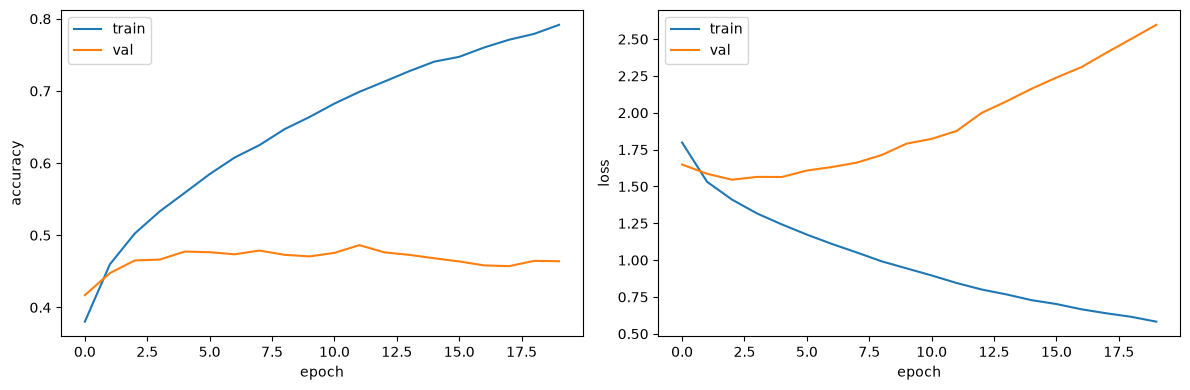

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(full_history.history["accuracy"], label="train")
axes[0].plot(full_history.history["val_accuracy"], label="val")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("accuracy")
axes[0].legend()

axes[1].plot(full_history.history["loss"], label="train")
axes[1].plot(full_history.history["val_loss"], label="val")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("loss")
axes[1].legend()

plt.tight_layout()
plt.show()

yllä olevista kuvaajista voimme päätellä `val_loss` noususta että malli ylioppii (overfit). Lisätään aikaisemppiin mallinkoulutuksiin callback joka pysäyttää ja palauttaa parametrit jolloin `val_loss` alkoi nousta.

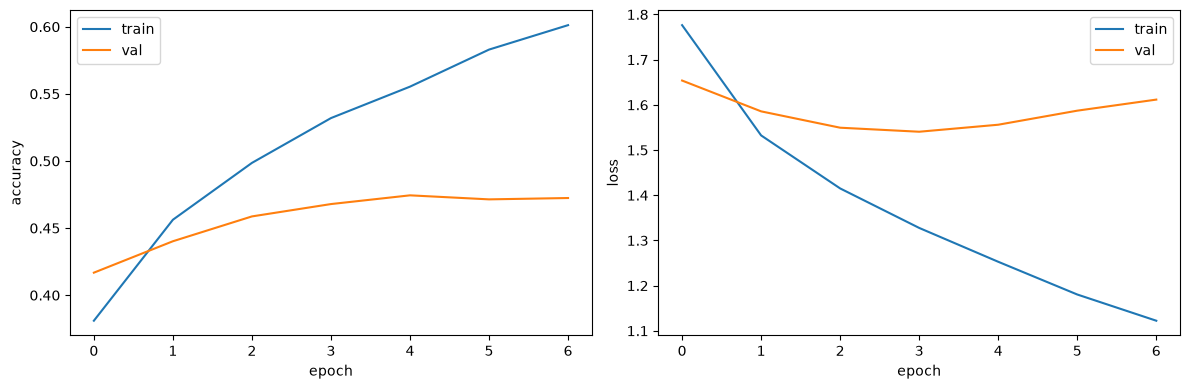

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="val")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="val")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("loss")
axes[1].legend()

plt.tight_layout()
plt.show()

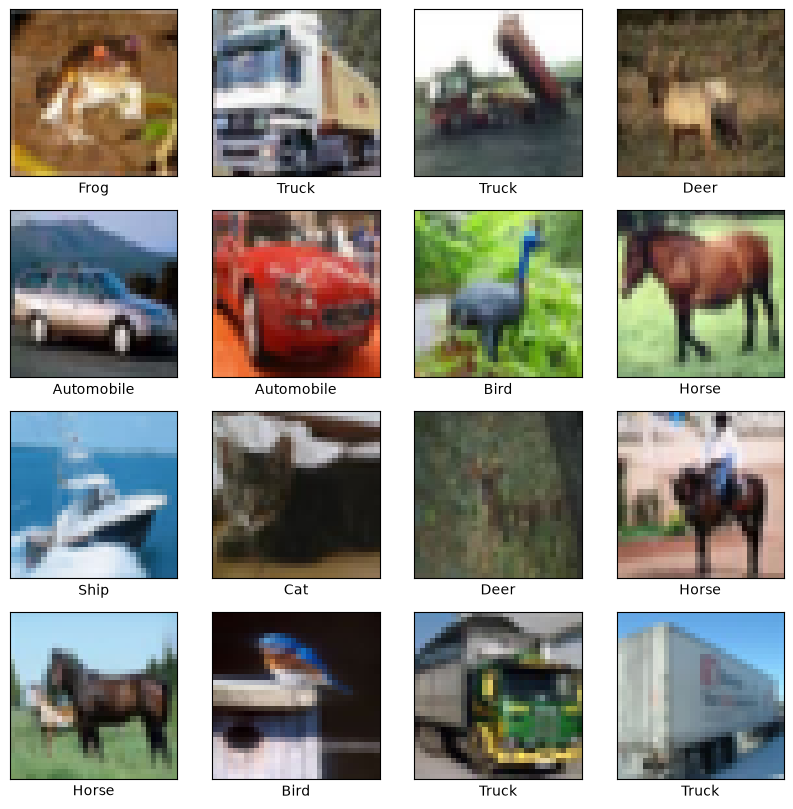

In [11]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

class_names = ['Airplane','Automobile','Bird','Cat','Deer','Dog','Frog','Horse','Ship','Truck']

plt.figure(figsize=(10,10))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    plt.xlabel(class_names[y_train[i][0]])
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 550us/step
(10000, 10) 1.0


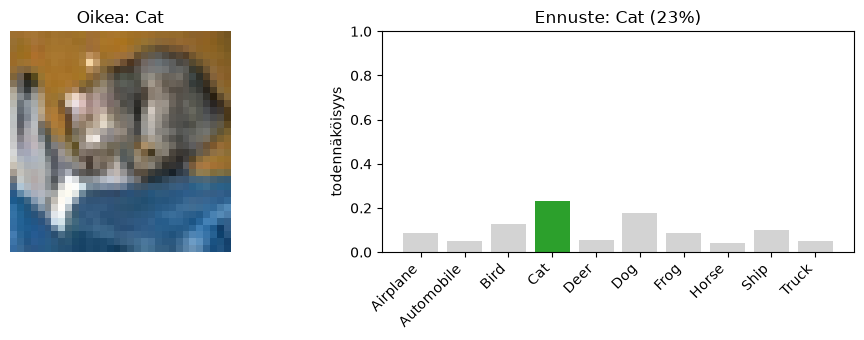

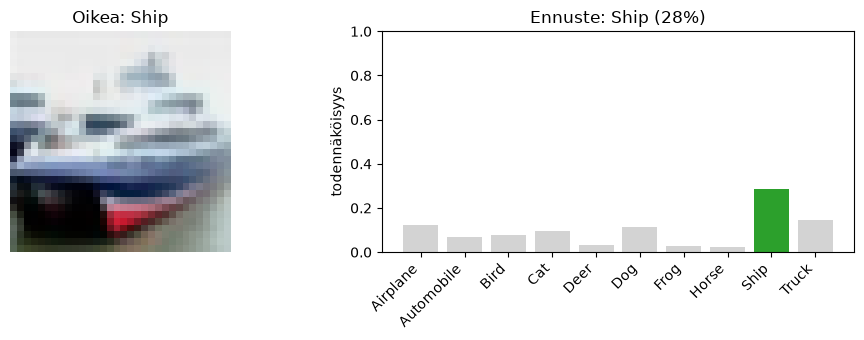

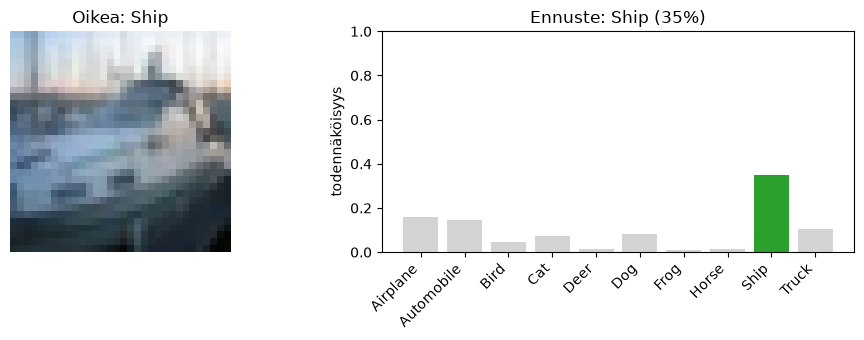

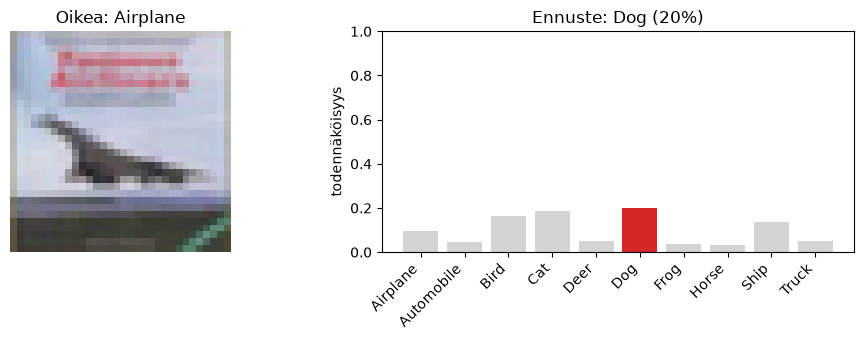

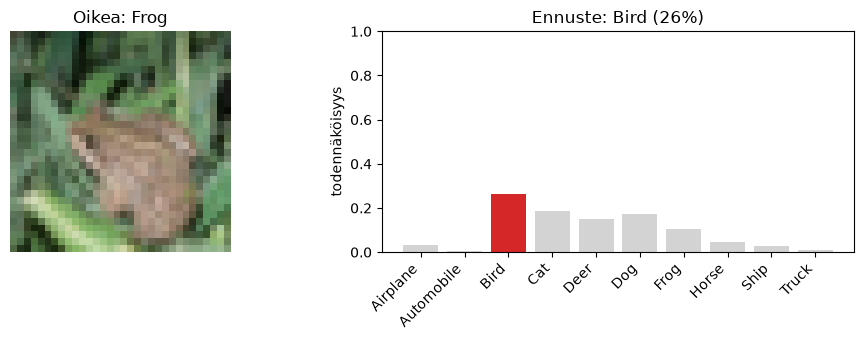

In [12]:
x_test_flat = x_test.reshape(10000, 3072)
probs = model.predict(x_test_flat)
print(probs.shape, probs[0].sum())

(_, _), (x_test_img, y_test_int) = keras.datasets.cifar10.load_data()
x_test_img = x_test_img.astype("float32") / 255
y_test_int = y_test_int.flatten()

def plot_prediction(i, probs, images_img, true_labels):
    pred = np.argmax(probs[i])
    true = true_labels[i]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

    ax1.imshow(images_img[i])
    ax1.axis("off")
    ax1.set_title(f"Oikea: {class_names[true]}")

    colors = ["lightgray"] * 10
    colors[pred] = "tab:red" if pred != true else "tab:green"
    ax2.bar(range(10), probs[i], color=colors)
    ax2.set_xticks(range(10))
    ax2.set_xticklabels(class_names, rotation=45, ha="right")
    ax2.set_ylim(0, 1)
    ax2.set_ylabel("todennäköisyys")
    ax2.set_title(f"Ennuste: {class_names[pred]} ({probs[i][pred]:.0%})")

    plt.tight_layout()
    plt.show()

for i in range(5):
    plot_prediction(i, probs, x_test_img, y_test_int)

## Tekoälyn käyttö
tekoälyä on käytetty koodien kirjoittamisen ja eri funktioden toimninnan ymmärtämisen apuna.